# Chapter 13: Probability and Random Variables — Interactive Coding & Exercise Companion

**Book**: *Mathematics for Artificial Intelligence* · **Chapter 13** (`chapter13-probability-and-random-variables`)  
**Environment**: `conda activate usao` (`numpy`, `scipy`, `matplotlib`, `torch`)

---

### What You Will Learn & Verify in This Notebook
1. **Part I — Classification Metrics, ROC/AUC & Joint Distributions (Exercises 1–5)**:
   - **Exercises 1 & 4**: 3-class confusion matrix ($N=129$), joint probability table, overall accuracy ($105/129 \approx 81.40\%$), per-class and macro-averaged Precision, Recall, F1, Specificity, and marginal prediction probability $P(\text{Pred}=\text{Dog}) = 34/129 \approx 26.36\%$.
   - **Exercise 2**: Binary classification confusion matrix at $t=0.5$, ROC curve across thresholds $t \in \{0.2, 0.4, 0.5, 0.6, 0.8\}$, and Mann–Whitney pairwise $\mathrm{AUC} = P(S_+ > S_-) = 19/25 = 0.76$.
   - **Exercises 3 & 5**: Piecewise joint CDF $F(x,y) = P(X\le x, Y\le y)$ and marginal PDFs $f_X(x) = \frac{3}{2}(1-x^2)$, $f_Y(y) = 3y^2$ for the triangular density $f(x,y)=3y$ on $0\le x\le y\le 1$, verified via 2D numerical quadrature and Monte Carlo inverse-CDF sampling.
2. **Part II — Directional Statistics (vMF), Calibration & Whitening (Exercises 6–8)**:
   - **Exercise 6**: von Mises-Fisher (vMF) distribution $f(\mathbf{x}\mid\boldsymbol{\mu},\kappa) = C_d(\kappa)\exp(\kappa\boldsymbol{\mu}^\top\mathbf{x})$ normalization on $\mathbb{S}^{d-1}$, density ratios at $[1,0,0]^\top$ vs. $[0,1,0]^\top$, uniform limit $\kappa\to 0$, 2D von Mises circular density, and spherical MLE $\hat{\boldsymbol{\mu}} = \bar{\mathbf{x}}/\|\bar{\mathbf{x}}\|_2$.
   - **Exercise 7**: Bin calibration, Brier score Murphy decomposition ($\mathrm{BS} = \text{Reliability} + \text{Refinement} = 0.090 + 0.240 = 0.330$), and logit temperature scaling $\operatorname{softmax}(\mathbf{z}/T)$ at $T=1$ vs. $T=2$.
   - **Exercise 8**: ZCA whitening $W_{\mathrm{ZCA}} = \Sigma^{-1/2}$ vs. PCA whitening $W_{\mathrm{PCA}} = \Lambda^{-1/2}U^\top$ on diagonal covariance $\Sigma = \operatorname{diag}(2, 1/2)$ and correlated 2D Gaussians.


In [1]:
import numpy as np
from scipy.integrate import dblquad, quad
from scipy.special import iv
import torch
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
print("NumPy version:", np.__version__)
print("PyTorch version:", torch.__version__)


NumPy version: 2.4.6
PyTorch version: 2.10.0+cu128


---
## Part I: Classification Metrics, ROC/AUC & Joint Distributions (Exercises 1–5)

### Exercises 1, 2 & 4: Multiclass Confusion Matrix, Marginal Prediction Probability & Binary ROC/AUC
1. **Exercises 1 & 4**: Given the 3-class confusion matrix $C \in \mathbb{R}^{3\times 3}$ (rows = Actual, cols = Predicted) with $N = 129$:
   $$\text{Accuracy} = \frac{\operatorname{tr}(C)}{N} = \frac{105}{129} \approx 0.8140, \qquad P(\text{Pred}=\text{Dog}) = \frac{\sum_i C_{i,0}}{N} = \frac{34}{129} \approx 0.2636.$$
2. **Exercise 2**: For positive scores $S_+ = \{0.95, 0.87, 0.76, 0.65, 0.45\}$ and negative scores $S_- = \{0.82, 0.71, 0.58, 0.33, 0.21\}$:
   $$\mathrm{AUC} = P(S_+ > S_-) = \frac{1}{|S_+||S_-|}\sum_{s_+\in S_+}\sum_{s_-\in S_-}\mathbb{I}(s_+ > s_-) = \frac{19}{25} = 0.76.$$


[Ex 1] Overall Accuracy = 105/129 = 0.8140
[Ex 4] Marginal P(Predict=Dog) = 34/129 = 0.2636
  Dog : Prec=0.8824, Rec=0.8108, F1=0.8451, Spec=0.9565
  Cat : Prec=0.7843, Rec=0.8000, F1=0.7921, Spec=0.8608
  Fish: Prec=0.7955, Rec=0.8333, F1=0.8140, Spec=0.8966
[Ex 1] Macro Avg: Prec=0.8207, Rec=0.8147, F1=0.8170, Spec=0.9046
[Ex 2] t=0.5: TP=4, FP=3, TN=2, FN=1 | Prec=0.5714, Rec=0.8000, Spec=0.4000, F1=0.6667
[Ex 2] Pairwise Mann-Whitney AUC = 19/25 = 0.7600


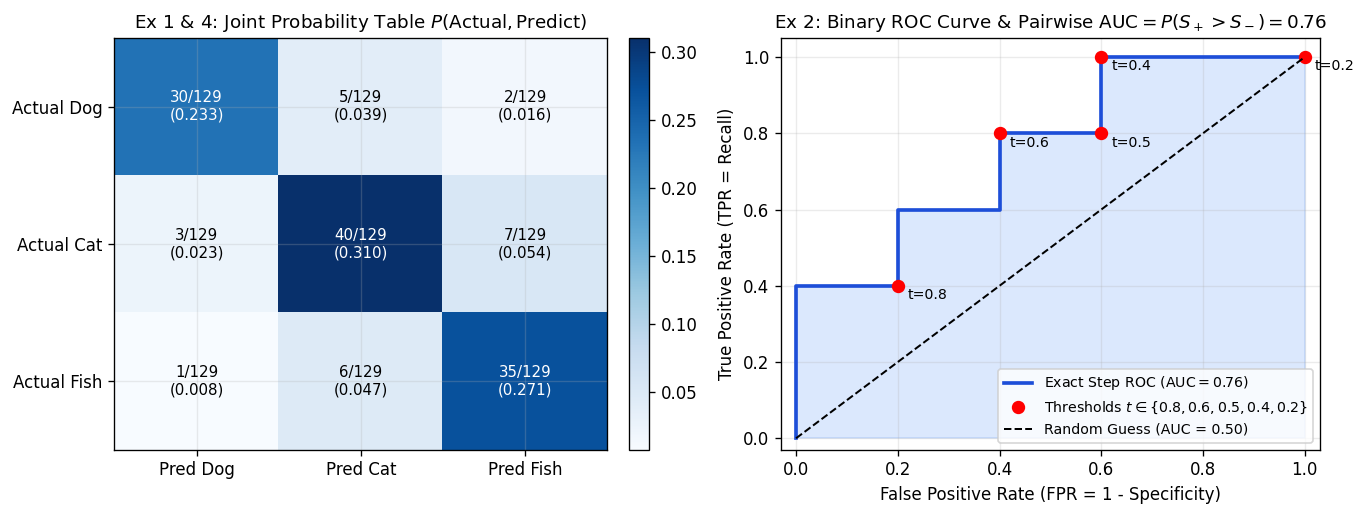

In [2]:
# Exercise 1 & 4: Multiclass confusion matrix analysis
classes = ["Dog", "Cat", "Fish"]
C = np.array([
    [30,  5,  2],
    [ 3, 40,  7],
    [ 1,  6, 35]
], dtype=float)
N_total = C.sum()
P_joint = C / N_total
acc = np.trace(C) / N_total
p_pred_dog = C[:, 0].sum() / N_total

tp = np.diag(C)
fp = C.sum(axis=0) - tp
fn = C.sum(axis=1) - tp
tn = N_total - (tp + fp + fn)
prec = tp / (tp + fp)
rec = tp / (tp + fn)
f1 = 2.0 * prec * rec / (prec + rec)
spec = tn / (tn + fp)

print(f"[Ex 1] Overall Accuracy = {int(np.trace(C))}/{int(N_total)} = {acc:.4f}")
print(f"[Ex 4] Marginal P(Predict=Dog) = {int(C[:,0].sum())}/{int(N_total)} = {p_pred_dog:.4f}")
for idx, cls in enumerate(classes):
    print(f"  {cls:4s}: Prec={prec[idx]:.4f}, Rec={rec[idx]:.4f}, F1={f1[idx]:.4f}, Spec={spec[idx]:.4f}")
print(f"[Ex 1] Macro Avg: Prec={prec.mean():.4f}, Rec={rec.mean():.4f}, F1={f1.mean():.4f}, Spec={spec.mean():.4f}")

# Exercise 2: Binary classification at t=0.5, ROC points, and Mann-Whitney AUC
pos_scores = np.array([0.95, 0.87, 0.76, 0.65, 0.45])
neg_scores = np.array([0.82, 0.71, 0.58, 0.33, 0.21])
tp_05 = int(np.sum(pos_scores >= 0.5))
fn_05 = int(np.sum(pos_scores < 0.5))
fp_05 = int(np.sum(neg_scores >= 0.5))
tn_05 = int(np.sum(neg_scores < 0.5))
prec_05 = tp_05 / (tp_05 + fp_05)
rec_05 = tp_05 / (tp_05 + fn_05)
spec_05 = tn_05 / (tn_05 + fp_05)
f1_05 = 2.0 * prec_05 * rec_05 / (prec_05 + rec_05)
concordant = int(np.sum(pos_scores[:, None] > neg_scores[None, :]))
auc_val = concordant / (len(pos_scores) * len(neg_scores))
print(f"[Ex 2] t=0.5: TP={tp_05}, FP={fp_05}, TN={tn_05}, FN={fn_05} | Prec={prec_05:.4f}, Rec={rec_05:.4f}, Spec={spec_05:.4f}, F1={f1_05:.4f}")
print(f"[Ex 2] Pairwise Mann-Whitney AUC = {concordant}/25 = {auc_val:.4f}")

thresholds = [1.0, 0.8, 0.6, 0.5, 0.4, 0.2, 0.0]
fpr_pts = [float(np.mean(neg_scores >= t)) for t in thresholds]
tpr_pts = [float(np.mean(pos_scores >= t)) for t in thresholds]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

# Left plot: Normalized Joint Probability Heatmap P(Actual, Predict)
im = axes[0].imshow(P_joint, cmap="Blues", aspect="auto")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{int(C[i,j])}/129\n({P_joint[i,j]:.3f})", ha="center", va="center",
                     color="white" if P_joint[i,j] > 0.18 else "black", fontsize=9)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels([f"Pred {c}" for c in classes])
axes[0].set_yticks(range(3))
axes[0].set_yticklabels([f"Actual {c}" for c in classes])
axes[0].set_title(r"Ex 1 & 4: Joint Probability Table $P(\mathrm{Actual}, \mathrm{Predict})$")

# Right plot: Binary ROC curve and AUC
all_thresh = np.sort(np.unique(np.concatenate([[1.01], pos_scores, neg_scores, [0.0]])))[::-1]
fpr_full = [np.mean(neg_scores >= t) for t in all_thresh]
tpr_full = [np.mean(pos_scores >= t) for t in all_thresh]
axes[1].plot(fpr_full, tpr_full, color="#1d4ed8", lw=2.2, label=rf"Exact Step ROC ($\mathrm{{AUC}} = {auc_val:.2f}$)")
axes[1].fill_between(fpr_full, tpr_full, alpha=0.18, color="#3b82f6")
axes[1].plot(fpr_pts[1:-1], tpr_pts[1:-1], "ro", markersize=7, label=r"Thresholds $t \in \{0.8, 0.6, 0.5, 0.4, 0.2\}$")
for t_v, fx, ty in zip(thresholds[1:-1], fpr_pts[1:-1], tpr_pts[1:-1]):
    axes[1].annotate(f"t={t_v}", (fx, ty), textcoords="offset points", xytext=(6, -8), fontsize=8.5)
axes[1].plot([0, 1], [0, 1], "k--", lw=1.2, label="Random Guess (AUC = 0.50)")
axes[1].set_xlim(-0.03, 1.03)
axes[1].set_ylim(-0.03, 1.05)
axes[1].set_title(r"Ex 2: Binary ROC Curve & Pairwise $\mathrm{AUC} = P(S_+ > S_-) = 0.76$")
axes[1].set_xlabel("False Positive Rate (FPR = 1 - Specificity)")
axes[1].set_ylabel("True Positive Rate (TPR = Recall)")
axes[1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()


---
### Exercises 3 & 5: Joint CDF $F(x,y)$ and Marginal PDFs $f_X(x), f_Y(y)$ from Triangular PDF
Given $f(x,y) = 3y$ on $0 \le x \le y \le 1$:
1. **Exercise 3 (Joint CDF)**:
   $$F(x,y) = P(X\le x, Y\le y) = \begin{cases} 0, & x \le 0 \text{ or } y \le 0, \\ \frac{x(3y^2 - x^2)}{2}, & 0 \le x \le y \le 1, \\ y^3, & 0 \le y < x \le 1, \\ \frac{x(3 - x^2)}{2}, & 0 \le x \le 1 < y, \\ 1, & x > 1 \text{ and } y > 1. \end{cases}$$
2. **Exercise 5 (Marginal PDFs)**:
   $$f_X(x) = \int_x^1 3y\,dy = \frac{3}{2}(1 - x^2)\quad (0\le x\le 1), \qquad f_Y(y) = \int_0^y 3y\,dx = 3y^2\quad (0\le y\le 1).$$


[Ex 3] F(0.3, 0.7): analytical = 0.207000, dblquad = 0.207000, diff = 0.00e+00
[Ex 3] F(0.7, 0.3): analytical = 0.027000, dblquad = 0.027000, diff = 3.47e-18
[Ex 3] F(0.6, 0.6): analytical = 0.216000, dblquad = 0.216000, diff = 8.33e-17
[Ex 3] F(1.0, 1.0): analytical = 1.000000, dblquad = 1.000000, diff = 0.00e+00
[Ex 5] E[X]: Monte Carlo = 0.3748 vs exact 3/8 = 0.3750
[Ex 5] E[Y]: Monte Carlo = 0.7500 vs exact 3/4 = 0.7500


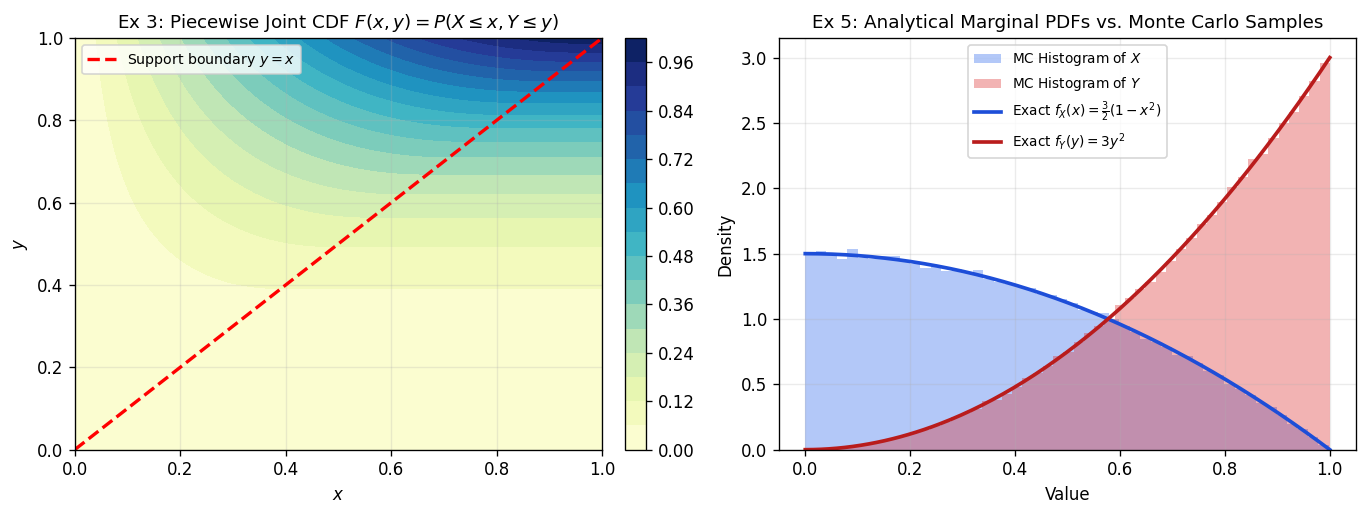

In [3]:
def F_joint_exact(x, y):
    if x <= 0.0 or y <= 0.0:
        return 0.0
    xc = min(x, 1.0)
    yc = min(y, 1.0)
    if xc <= yc:
        return 0.5 * xc * (3.0 * (yc ** 2) - (xc ** 2))
    else:
        return yc ** 3

def F_joint_quad(x, y):
    if x <= 0.0 or y <= 0.0:
        return 0.0
    xc, yc = min(x, 1.0), min(y, 1.0)
    val, _ = dblquad(lambda v, u: 3.0 * v, 0.0, min(xc, yc), lambda u: u, lambda u: yc)
    return val

for xp, yp in [(0.3, 0.7), (0.7, 0.3), (0.6, 0.6), (1.0, 1.0)]:
    f_ex = F_joint_exact(xp, yp)
    f_qu = F_joint_quad(xp, yp)
    print(f"[Ex 3] F({xp:.1f}, {yp:.1f}): analytical = {f_ex:.6f}, dblquad = {f_qu:.6f}, diff = {abs(f_ex - f_qu):.2e}")

# Exercise 5: Inverse-CDF Monte Carlo sampling vs exact marginal PDFs
rng = np.random.default_rng(42)
N_samples = 200_000
Y_sim = rng.uniform(0.0, 1.0, N_samples) ** (1.0 / 3.0)
X_sim = rng.uniform(0.0, Y_sim)
print(f"[Ex 5] E[X]: Monte Carlo = {X_sim.mean():.4f} vs exact 3/8 = {3/8:.4f}")
print(f"[Ex 5] E[Y]: Monte Carlo = {Y_sim.mean():.4f} vs exact 3/4 = {3/4:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

# Left plot: Joint CDF F(x, y) contour map on [0, 1]^2
gx, gy = np.meshgrid(np.linspace(0.0, 1.0, 100), np.linspace(0.0, 1.0, 100))
FZ = np.vectorize(F_joint_exact)(gx, gy)
cs = axes[0].contourf(gx, gy, FZ, levels=16, cmap="YlGnBu")
plt.colorbar(cs, ax=axes[0], fraction=0.046, pad=0.04)
axes[0].plot([0, 1], [0, 1], "r--", lw=2.0, label=r"Support boundary $y = x$")
axes[0].set_title(r"Ex 3: Piecewise Joint CDF $F(x, y) = P(X \leq x, Y \leq y)$")
axes[0].set_xlabel(r"$x$")
axes[0].set_ylabel(r"$y$")
axes[0].legend(loc="upper left", fontsize=8.5)

# Right plot: Marginal PDFs f_X(x) and f_Y(y) vs Monte Carlo histograms
grid_t = np.linspace(0.0, 1.0, 200)
axes[1].hist(X_sim, bins=50, density=True, alpha=0.35, color="#2563eb", label=r"MC Histogram of $X$")
axes[1].hist(Y_sim, bins=50, density=True, alpha=0.35, color="#dc2626", label=r"MC Histogram of $Y$")
axes[1].plot(grid_t, 1.5 * (1.0 - grid_t**2), color="#1d4ed8", lw=2.2, label=r"Exact $f_X(x) = \frac{3}{2}(1-x^2)$")
axes[1].plot(grid_t, 3.0 * grid_t**2, color="#b91c1c", lw=2.2, label=r"Exact $f_Y(y) = 3y^2$")
axes[1].set_title(r"Ex 5: Analytical Marginal PDFs vs. Monte Carlo Samples")
axes[1].set_xlabel("Value")
axes[1].set_ylabel("Density")
axes[1].legend(loc="upper center", fontsize=8.2)

plt.tight_layout()
plt.show()


---
## Part II: Directional Statistics, Calibration & Whitening (Exercises 6–8)

### Exercise 6: von Mises-Fisher (vMF) Distribution on the Unit Sphere
For $\mathbf{x}, \boldsymbol{\mu} \in \mathbb{S}^{d-1}$ and concentration $\kappa \ge 0$:
$$f(\mathbf{x}\mid\boldsymbol{\mu},\kappa) = C_d(\kappa)\exp(\kappa\boldsymbol{\mu}^\top\mathbf{x}), \qquad C_d(\kappa) = \frac{\kappa^{d/2-1}}{(2\pi)^{d/2}I_{d/2-1}(\kappa)}, \qquad \hat{\boldsymbol{\mu}}_{\mathrm{MLE}} = \frac{\bar{\mathbf{x}}}{\|\bar{\mathbf{x}}\|_2}.$$


[Ex 6.1] Surface integral over S^2             = 1.000000
[Ex 6.2] 3D vMF(kappa=2): f(mu) = 0.3242, f(orth) = 0.0439, ratio = 7.3891 (e^2=7.3891)
[Ex 6.3] Limit kappa->0: C_3(1e-6) = 0.079577 == 1/(4*pi) = 0.079577
[Ex 6.4] 2D vM(mu=pi/2, kappa=1): f(pi/2) = 0.3417, f(0) = 0.1257
[Ex 6.5] True mu = [0. 1.], Euclidean mean x_bar = [-0.0023  0.8374] (||x_bar||_2=0.8374<1), Normalized MLE = [-0.0027  1.    ]


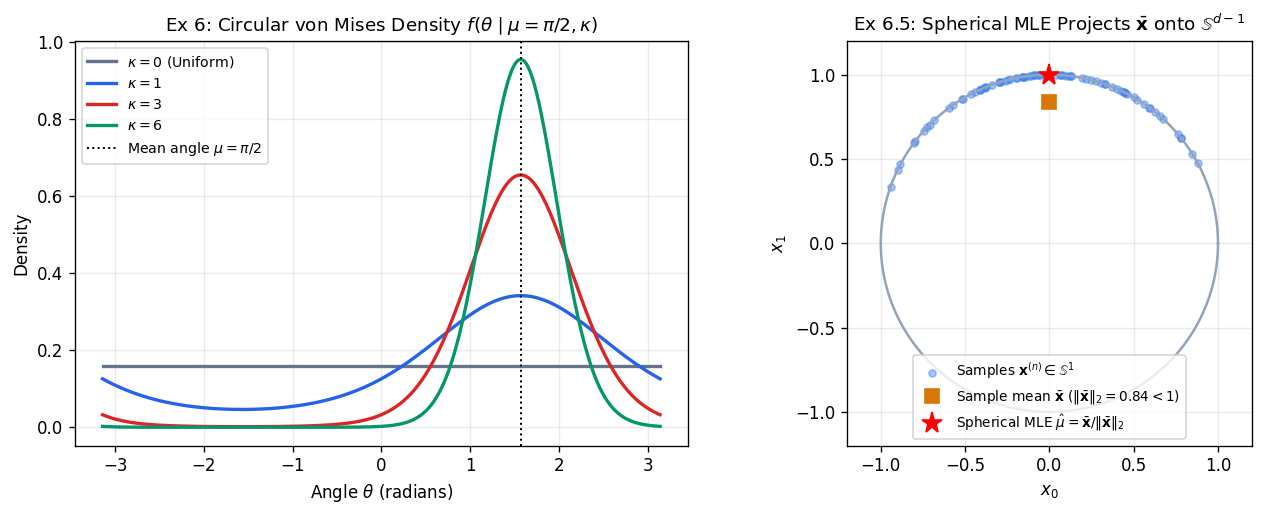

In [4]:
# Exercise 6: 3D vMF (d=3, kappa=2) and 2D von Mises (d=2, mu=pi/2, kappa=1)
kappa_3d = 2.0
C3 = kappa_3d / (4.0 * np.pi * np.sinh(kappa_3d))
int_sphere, _ = quad(lambda th: C3 * np.exp(kappa_3d * np.cos(th)) * 2.0 * np.pi * np.sin(th), 0.0, np.pi)
f_mean_3d = C3 * np.exp(kappa_3d * 1.0)
f_orth_3d = C3 * np.exp(kappa_3d * 0.0)
print(f"[Ex 6.1] Surface integral over S^2             = {int_sphere:.6f}")
print(f"[Ex 6.2] 3D vMF(kappa=2): f(mu) = {f_mean_3d:.4f}, f(orth) = {f_orth_3d:.4f}, ratio = {f_mean_3d/f_orth_3d:.4f} (e^2={np.exp(2):.4f})")
print(f"[Ex 6.3] Limit kappa->0: C_3(1e-6) = {1e-6/(4*np.pi*np.sinh(1e-6)):.6f} == 1/(4*pi) = {1/(4*np.pi):.6f}")

C2 = 1.0 / (2.0 * np.pi * iv(0, 1.0))
f_pi2 = C2 * np.exp(1.0 * np.cos(0.0))
f_0 = C2 * np.exp(1.0 * np.cos(-np.pi / 2.0))
print(f"[Ex 6.4] 2D vM(mu=pi/2, kappa=1): f(pi/2) = {f_pi2:.4f}, f(0) = {f_0:.4f}")

# Exercise 6.5: Spherical MLE on synthetic vMF samples
mu_true = np.array([0.0, 1.0])
angles = rng.vonmises(mu=np.pi / 2.0, kappa=3.0, size=400)
X_circle = np.stack([np.cos(angles), np.sin(angles)], axis=1)
x_bar = X_circle.mean(axis=0)
mu_hat = x_bar / np.linalg.norm(x_bar)
print(f"[Ex 6.5] True mu = {mu_true}, Euclidean mean x_bar = {x_bar} (||x_bar||_2={np.linalg.norm(x_bar):.4f}<1), Normalized MLE = {mu_hat}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

# Left plot: 2D von Mises density across concentration kappa
theta_grid = np.linspace(-np.pi, np.pi, 300)
for kp, col in [(0.0, "#64748b"), (1.0, "#2563eb"), (3.0, "#dc2626"), (6.0, "#059669")]:
    c_k = 1.0 / (2.0 * np.pi * iv(0, kp))
    axes[0].plot(theta_grid, c_k * np.exp(kp * np.cos(theta_grid - np.pi / 2.0)), lw=2.0, color=col,
                 label=rf"$\kappa = {kp:.0f}$" + (" (Uniform)" if kp == 0 else ""))
axes[0].axvline(np.pi / 2.0, color="k", ls=":", lw=1.2, label=r"Mean angle $\mu = \pi/2$")
axes[0].set_title(r"Ex 6: Circular von Mises Density $f(\theta \mid \mu=\pi/2, \kappa)$")
axes[0].set_xlabel(r"Angle $\theta$ (radians)")
axes[0].set_ylabel("Density")
axes[0].legend(loc="upper left", fontsize=8.5)

# Right plot: Unit circle samples, Euclidean mean inside disk vs projected spherical MLE on S^1
circle_t = np.linspace(0, 2 * np.pi, 200)
axes[1].plot(np.cos(circle_t), np.sin(circle_t), color="#94a3b8", lw=1.5)
axes[1].scatter(X_circle[:80, 0], X_circle[:80, 1], s=18, alpha=0.45, color="#3b82f6", label=r"Samples $\mathbf{x}^{(n)} \in \mathbb{S}^1$")
axes[1].plot(x_bar[0], x_bar[1], "s", color="#d97706", markersize=8, label=rf"Sample mean $\bar{{\mathbf{{x}}}}$ ($\|\bar{{\mathbf{{x}}}}\|_2={np.linalg.norm(x_bar):.2f} < 1$)")
axes[1].plot(mu_hat[0], mu_hat[1], "r*", markersize=13, label=r"Spherical MLE $\hat{\mu} = \bar{\mathbf{x}}/\|\bar{\mathbf{x}}\|_2$")
axes[1].set_aspect("equal")
axes[1].set_xlim(-1.2, 1.2)
axes[1].set_ylim(-1.2, 1.2)
axes[1].set_title(r"Ex 6.5: Spherical MLE Projects $\bar{\mathbf{x}}$ onto $\mathbb{S}^{d-1}$")
axes[1].set_xlabel(r"$x_0$")
axes[1].set_ylabel(r"$x_1$")
axes[1].legend(loc="lower center", fontsize=8.2)

plt.tight_layout()
plt.show()


---
### Exercises 7 & 8: Calibration, Brier Score Murphy Decomposition, Temperature Scaling & Whitening
1. **Exercise 7**:
   $$\mathrm{BS} = \frac{1}{N}\sum_{i=1}^N (f_i - y_i)^2 = \underbrace{\frac{1}{N}\sum_m |B_m|(\bar{f}_m - \bar{y}_m)^2}_{\text{Reliability}} + \underbrace{\frac{1}{N}\sum_m |B_m|\bar{y}_m(1 - \bar{y}_m)}_{\text{Refinement}}.$$
2. **Exercise 8**:
   $$W_{\mathrm{ZCA}} = \Sigma^{-1/2} = U\Lambda^{-1/2}U^\top, \qquad W_{\mathrm{PCA}} = \Lambda^{-1/2}U^\top, \qquad \operatorname{Cov}[W_{\mathrm{ZCA}}X] = \operatorname{Cov}[W_{\mathrm{PCA}}X] = I_2.$$


[Ex 7.1 & 7.3] Brier Score = 0.3300 == Reliability (0.0900) + Refinement (0.2400) = 0.3300
[Ex 7.2] T=0.5: probs = [0.982 0.018], argmax = 0
[Ex 7.2] T=1.0: probs = [0.8808 0.1192], argmax = 0
[Ex 7.2] T=2.0: probs = [0.7311 0.2689], argmax = 0
[Ex 7.2] T=5.0: probs = [0.5987 0.4013], argmax = 0
[Ex 8.1] W_ZCA = diag([0.7071 1.4142]), ||W_ZCA Sigma W_ZCA^T - I||_F = 8.43e-08
[Ex 8.2] ||W_PCA - W_ZCA||_F on diagonal Sigma = 0.00e+00


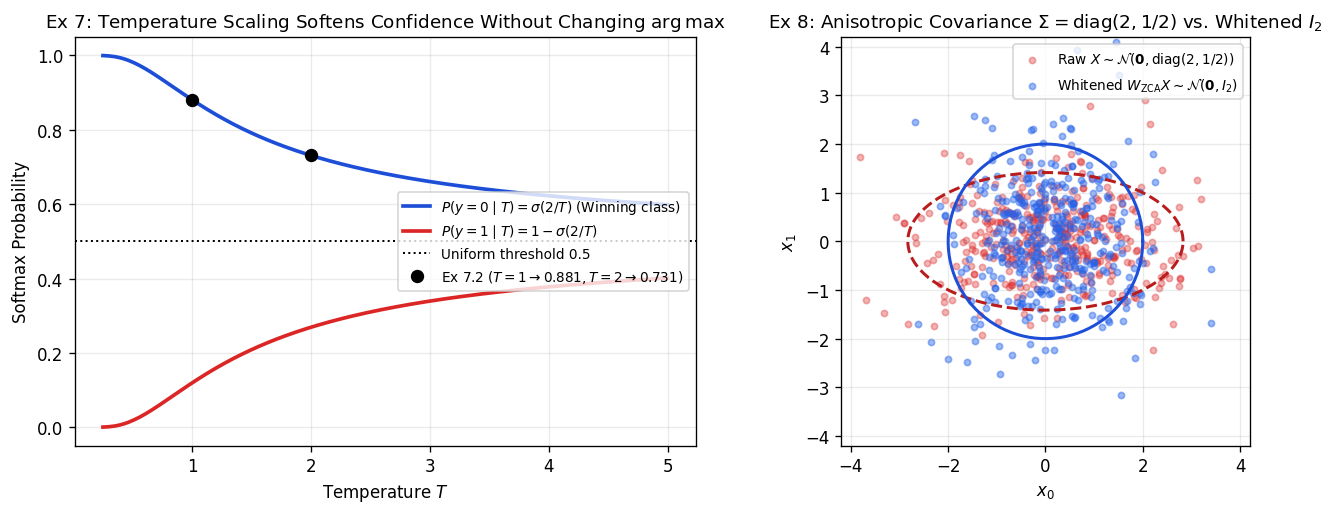

In [5]:
# Exercise 7: Calibration, Murphy Brier decomposition & Temperature scaling
y_bin = torch.tensor([1., 1., 1., 1., 1., 1., 0., 0., 0., 0.])
f_bin = torch.full((10,), 0.9)
bs_val = torch.mean((f_bin - y_bin) ** 2).item()
rel_val = ((f_bin.mean() - y_bin.mean()) ** 2).item()
ref_val = (y_bin.mean() * (1.0 - y_bin.mean())).item()
print(f"[Ex 7.1 & 7.3] Brier Score = {bs_val:.4f} == Reliability ({rel_val:.4f}) + Refinement ({ref_val:.4f}) = {rel_val + ref_val:.4f}")

logits7 = torch.tensor([2.0, 0.0])
for T_val in (0.5, 1.0, 2.0, 5.0):
    p_t = torch.softmax(logits7 / T_val, dim=-1)
    print(f"[Ex 7.2] T={T_val:3.1f}: probs = {p_t.numpy().round(4)}, argmax = {int(p_t.argmax())}")

# Exercise 8: ZCA and PCA whitening on diagonal Sigma = diag(2, 1/2)
Sigma8 = torch.tensor([[2.0, 0.0], [0.0, 0.5]])
lam8, U8 = torch.linalg.eigh(Sigma8)
lam8, U8 = lam8.flip(0), U8.flip(1)
U8 = U8 * torch.sign(torch.diagonal(U8))
inv_sqrt8 = torch.diag(lam8.rsqrt())
W_pca8 = inv_sqrt8 @ U8.T
W_zca8 = U8 @ inv_sqrt8 @ U8.T
print(f"[Ex 8.1] W_ZCA = diag({torch.diagonal(W_zca8).numpy().round(4)}), ||W_ZCA Sigma W_ZCA^T - I||_F = {torch.norm(W_zca8 @ Sigma8 @ W_zca8.T - torch.eye(2)).item():.2e}")
print(f"[Ex 8.2] ||W_PCA - W_ZCA||_F on diagonal Sigma = {torch.norm(W_pca8 - W_zca8).item():.2e}")

torch.manual_seed(0)
X_raw = torch.randn(2000, 2) @ torch.linalg.cholesky(Sigma8).T
X_white = X_raw @ W_zca8.T

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

# Left plot: Temperature scaling effect on binary probabilities for z = (2, 0)
T_grid = np.linspace(0.25, 5.0, 200)
p0_curve = 1.0 / (1.0 + np.exp(-2.0 / T_grid))
p1_curve = 1.0 - p0_curve
axes[0].plot(T_grid, p0_curve, color="#1d4ed8", lw=2.2, label=r"$P(y=0 \mid T) = \sigma(2/T)$ (Winning class)")
axes[0].plot(T_grid, p1_curve, color="#dc2626", lw=2.2, label=r"$P(y=1 \mid T) = 1 - \sigma(2/T)$")
axes[0].axhline(0.5, color="black", ls=":", lw=1.2, label="Uniform threshold 0.5")
axes[0].plot([1.0, 2.0], [1.0/(1.0+np.exp(-2.0)), 1.0/(1.0+np.exp(-1.0))], "ko", markersize=7, label=r"Ex 7.2 ($T=1 \to 0.881, T=2 \to 0.731$)")
axes[0].set_title(r"Ex 7: Temperature Scaling Softens Confidence Without Changing $\arg\max$")
axes[0].set_xlabel(r"Temperature $T$")
axes[0].set_ylabel("Softmax Probability")
axes[0].legend(loc="center right", fontsize=8.2)

# Right plot: Original anisotropic cloud Sigma = diag(2, 1/2) vs ZCA/PCA whitened isotropic cloud
axes[1].scatter(X_raw[:400, 0].numpy(), X_raw[:400, 1].numpy(), s=14, alpha=0.35, color="#dc2626", label=r"Raw $X \sim \mathcal{N}(\mathbf{0}, \mathrm{diag}(2, 1/2))$")
axes[1].scatter(X_white[:400, 0].numpy(), X_white[:400, 1].numpy(), s=14, alpha=0.45, color="#2563eb", label=r"Whitened $W_{\mathrm{ZCA}}X \sim \mathcal{N}(\mathbf{0}, I_2)$")
ang = np.linspace(0, 2 * np.pi, 200)
axes[1].plot(2.0 * np.sqrt(2.0) * np.cos(ang), 2.0 * np.sqrt(0.5) * np.sin(ang), "--", color="#b91c1c", lw=1.8)
axes[1].plot(2.0 * np.cos(ang), 2.0 * np.sin(ang), "-", color="#1d4ed8", lw=1.8)
axes[1].set_aspect("equal")
axes[1].set_xlim(-4.2, 4.2)
axes[1].set_ylim(-4.2, 4.2)
axes[1].set_title(r"Ex 8: Anisotropic Covariance $\Sigma = \mathrm{diag}(2, 1/2)$ vs. Whitened $I_2$")
axes[1].set_xlabel(r"$x_0$")
axes[1].set_ylabel(r"$x_1$")
axes[1].legend(loc="upper right", fontsize=8.2)

plt.tight_layout()
plt.show()
